# Jaipur Junction-Informed Railway Platform Allocation — Benchmark v4

**Purpose:** diagnose whether the poor SA/SQA solution quality in v3 is caused partly by random initialization, and test whether a valid starting assignment helps.

**Methods in this notebook**
1. Exact classical constrained search — reference optimum on small instances.
2. OpenJij Simulated Annealing (SA) — cold-start and, when supported by the installed OpenJij version, warm-start.
3. OpenJij Simulated Quantum Annealing (SQA) — cold-start and, when supported, warm-start.
4. A small randomized greedy graph-colouring heuristic — used only to produce a valid warm-start candidate and as a transparent classical baseline. It is not an exact solver.

## Important methodological safeguards
- V4 recreates the **same 27 dataset settings** as v3: 8, 10, and 12 trains; maximum delays of 5, 10, and 15 minutes; seeds 11, 22, and 33; four abstract long-train-capable platforms.
- The train-level timetable, delays, platform assignments, and coach counts remain synthetic. This is a Jaipur-historical-profile-informed benchmark, not an actual Jaipur working timetable reconstruction.
- The railway constraints and reassignment objective are unchanged from v3.
- The greedy initializer does **not** use the Exact Search assignment. Exact Search is used only afterward to evaluate its cost.
- Warm starts are generated by taking the greedy feasible assignment and making up to three additional **valid** platform changes. This makes the starting point feasible but deliberately less polished, so we can test whether an annealer can improve it.
- If the installed OpenJij API does not accept `initial_state`, v4 records that limitation and skips warm-start calls rather than silently pretending they ran.
- No quantum hardware is used. OpenJij SQA is a classical simulation of quantum annealing.

**Decision:** do not enable the 28-train benchmark from this notebook yet. First review whether greedy initialization, warm-started SA, or warm-started SQA can recover the exact small-instance solutions.

## 0. Install dependencies

Run this cell once if needed, then restart the kernel if VS Code asks you to.

In [1]:
%pip install -q openjij numpy pandas matplotlib psutil

Note: you may need to restart the kernel to use updated packages.


## 1. Imports and machine information

In [2]:
import sys, platform, time, itertools, math, json, os, random, importlib.metadata
from pathlib import Path
from typing import Dict, List, Tuple, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import openjij as oj
except ImportError as exc:
    raise ImportError("OpenJij is required. Install it in this notebook kernel, then restart the kernel.") from exc

try:
    OPENJIJ_VERSION = importlib.metadata.version("openjij")
except Exception:
    OPENJIJ_VERSION = getattr(oj, "__version__", "version not exposed")

try:
    import psutil
    RAM_GB = round(psutil.virtual_memory().total / 1024**3, 2)
except Exception:
    RAM_GB = None

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("CPU:", platform.processor() or "not exposed")
print("RAM (GB):", RAM_GB if RAM_GB is not None else "not measured")
print("OpenJij:", OPENJIJ_VERSION)
try:
    import torch
    print("CUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
except Exception:
    print("PyTorch/CUDA: not installed; this notebook's OpenJij SA/SQA runs are CPU sampler calls.")

Python: 3.12.12
Platform: Windows-11-10.0.26300-SP0
CPU: Intel64 Family 6 Model 143 Stepping 8, GenuineIntel
RAM (GB): 127.65
OpenJij: 0.12.2
PyTorch/CUDA: not installed; this notebook's OpenJij SA/SQA runs are CPU sampler calls.


## 2. Experiment settings

The dataset definitions intentionally match v3. V4 adds initialization modes; it does not change the train data or QUBO.

In [3]:
# Historical-profile assumptions
N_PLATFORMS = 6
PEAK_WINDOW_START = 12 * 60
PEAK_WINDOW_END = 18 * 60
BASE_CLEARANCE_MIN = 5                 # experimental assumption; not a verified Jaipur rule
LONG_TRAIN_COACH_THRESHOLD = 24
LONG_PLATFORM_COUNT_MAIN = 4           # abstract eligibility assumption; v3 main case

# Exact same 27-dataset pilot as v3
TRAIN_COUNTS = [8, 10, 12]
DELAY_LEVELS_MIN = [5, 10, 15]
DATASET_SEEDS = [11, 22, 33]

# Main sampler experiment
SOLVER_REPEATS = 2
NUM_READS = 100
NUM_SWEEPS = 500
EXACT_TIME_LIMIT_S = 30
PENALTY_RULE = "N + 1"

# Warm-start generation: create a valid initial assignment, then degrade it carefully
GREEDY_RESTARTS = 100
WARM_START_PERTURBATIONS = 3

# Extra compute-effort check on one selected difficult feasible dataset
RUN_EFFORT_SENSITIVITY = True
CALIBRATION_REPEATS = 2
EFFORT_CONFIGS = [(100, 500), (300, 1000), (500, 2000)]

# Full Jaipur-profile workload is deliberately disabled
RUN_28_TRAIN_BENCHMARK = False

print("Unique pilot datasets:", len(TRAIN_COUNTS) * len(DELAY_LEVELS_MIN) * len(DATASET_SEEDS))
print("Expected main sampler records if all warm starts are supported:",
      len(TRAIN_COUNTS) * len(DELAY_LEVELS_MIN) * len(DATASET_SEEDS) * 2 * 2 * SOLVER_REPEATS)
print("Sufficient mathematical penalty for N trains: lambda > N, provided a feasible assignment exists.")

Unique pilot datasets: 27
Expected main sampler records if all warm starts are supported: 216
Sufficient mathematical penalty for N trains: lambda > N, provided a feasible assignment exists.


## 3. Recreate the v3 synthetic generator

The generator below is intentionally kept the same as v3 so the comparison is paired. The nominal timetable is conflict-free on each assigned platform after the five-minute clearance assumption. Actual arrival and departure are shifted together by the same randomly generated delay.

In [4]:
def scheduled_same_platform_conflicts(df: pd.DataFrame, clearance_min: int):
    conflicts = []
    for i in range(len(df)):
        si = int(df.iloc[i].scheduled_arrival_min)
        ei = int(df.iloc[i].scheduled_departure_min) + clearance_min
        for j in range(i + 1, len(df)):
            if int(df.iloc[i].nominal_platform) != int(df.iloc[j].nominal_platform):
                continue
            sj = int(df.iloc[j].scheduled_arrival_min)
            ej = int(df.iloc[j].scheduled_departure_min) + clearance_min
            if max(si, sj) < min(ei, ej):
                conflicts.append((i, j))
    return conflicts


def generate_jaipur_profile_instance(
    n_trains: int,
    seed: int,
    delay_max_min: int,
    long_platform_count: int = LONG_PLATFORM_COUNT_MAIN,
    long_train_count: Optional[int] = None,
    clearance_min: int = BASE_CLEARANCE_MIN,
    n_platforms: int = N_PLATFORMS,
) -> pd.DataFrame:
    """Create one reproducible, Jaipur-historical-profile-informed synthetic instance."""
    if n_trains < 1:
        raise ValueError("n_trains must be positive")
    if not 1 <= long_platform_count <= n_platforms:
        raise ValueError("long_platform_count must be between 1 and n_platforms")
    if delay_max_min < 0 or clearance_min < 0:
        raise ValueError("delay and clearance must be non-negative")

    rng = np.random.default_rng(seed)
    if long_train_count is None:
        # Proportional calibration from historical daily aggregate (18/97); not an observed peak-block count.
        long_train_count = min(n_trains, max(1, round(n_trains * 18 / 97)))
    if not 0 <= long_train_count <= n_trains:
        raise ValueError("long_train_count must be between 0 and n_trains")

    long_flags = np.array([True] * long_train_count + [False] * (n_trains - long_train_count))
    rng.shuffle(long_flags)
    long_eligible = set(range(long_platform_count))
    eligible = [sorted(long_eligible) if flag else list(range(n_platforms)) for flag in long_flags]

    # Load-balanced nominal platform assignment respecting train length eligibility.
    platform_load = np.zeros(n_platforms, dtype=int)
    nominal_platforms = []
    for i in range(n_trains):
        candidates = eligible[i]
        min_load = min(platform_load[p] for p in candidates)
        choices = [p for p in candidates if platform_load[p] == min_load]
        chosen = int(rng.choice(choices))
        nominal_platforms.append(chosen)
        platform_load[chosen] += 1

    arr_nom = np.zeros(n_trains, dtype=int)
    dep_nom = np.zeros(n_trains, dtype=int)
    for p in range(n_platforms):
        idxs = [i for i, pp in enumerate(nominal_platforms) if pp == p]
        if not idxs:
            continue
        rng.shuffle(idxs)
        count = len(idxs)
        n_small_gaps = (count - 1 + 1) // 2
        n_large_gaps = (count - 1) // 2
        max_span = (count * (22 + clearance_min) + n_small_gaps * 5 + n_large_gaps * 60)
        latest_start_offset = max(0, (PEAK_WINDOW_END - PEAK_WINDOW_START) - max_span)
        cursor = PEAK_WINDOW_START + int(rng.integers(0, latest_start_offset + 1))
        for position, i in enumerate(idxs):
            if position > 0:
                previous_position = position - 1
                gap = int(rng.integers(1, 6)) if previous_position % 2 == 0 else int(rng.integers(30, 61))
                cursor += gap
            dwell = int(rng.integers(12, 23))
            arr_nom[i] = cursor
            dep_nom[i] = cursor + dwell
            cursor = dep_nom[i] + clearance_min

    delays = rng.integers(0, delay_max_min + 1, size=n_trains)
    arr_actual = arr_nom + delays
    dep_actual = dep_nom + delays

    coach_draws = rng.choice([12, 16, 18, 22, 24, 26], size=n_trains, p=[.08, .15, .22, .20, .22, .13])
    coaches = np.where(long_flags, np.maximum(coach_draws, LONG_TRAIN_COACH_THRESHOLD), np.minimum(coach_draws, 22))

    rows = []
    for i in range(n_trains):
        rows.append({
            "train_index": i,
            "train_id": f"J{i+1:02d}",
            "coaches": int(coaches[i]),
            "is_long": bool(long_flags[i]),
            "nominal_platform": int(nominal_platforms[i]),
            "eligible_platforms": list(eligible[i]),
            "scheduled_arrival_min": int(arr_nom[i]),
            "scheduled_departure_min": int(dep_nom[i]),
            "delay_min": int(delays[i]),
            "actual_arrival_min": int(arr_actual[i]),
            "actual_departure_min": int(dep_actual[i]),
        })
    df = pd.DataFrame(rows)
    planned_conflicts = scheduled_same_platform_conflicts(df, clearance_min)
    if planned_conflicts:
        raise AssertionError(f"Generator created overlapping nominal intervals: {planned_conflicts}")
    return df


def interval_conflicts(df: pd.DataFrame, clearance_min: int) -> List[Tuple[int, int]]:
    """Return pairs whose actual occupation-plus-clearance intervals overlap."""
    conflicts = []
    for i in range(len(df)):
        si = int(df.iloc[i].actual_arrival_min)
        ei = int(df.iloc[i].actual_departure_min) + clearance_min
        for j in range(i + 1, len(df)):
            sj = int(df.iloc[j].actual_arrival_min)
            ej = int(df.iloc[j].actual_departure_min) + clearance_min
            if max(si, sj) < min(ei, ej):
                conflicts.append((i, j))
    return conflicts


def nominal_conflicts_after_delay(df: pd.DataFrame, conflicts: List[Tuple[int, int]]):
    return [(i, j) for i, j in conflicts
            if int(df.iloc[i].nominal_platform) == int(df.iloc[j].nominal_platform)]


def validate_assignment(assignment: Dict[int, int], df: pd.DataFrame, conflicts: List[Tuple[int, int]]):
    n = len(df)
    if assignment is None or set(assignment) != set(range(n)):
        return False, ["not_every_train_assigned"]
    violations = []
    for i, p in assignment.items():
        if int(p) not in [int(x) for x in df.iloc[i].eligible_platforms]:
            violations.append(f"ineligible_platform_train_{i}")
    for i, j in conflicts:
        if assignment.get(i) == assignment.get(j):
            violations.append(f"platform_conflict_{i}_{j}")
    return len(violations) == 0, violations


def assignment_cost(assignment: Dict[int, int], df: pd.DataFrame) -> int:
    return int(sum(int(assignment[i]) != int(df.iloc[i].nominal_platform) for i in range(len(df))))


def classify_exact_outcome(exact_result: dict) -> str:
    if exact_result["status"] == "TIMEOUT":
        return "UNKNOWN_TIMEOUT"
    if exact_result["status"] == "INFEASIBLE":
        return "INFEASIBLE"
    if exact_result["status"] != "OPTIMAL":
        return "UNKNOWN"
    return "NO_REASSIGNMENT_NEEDED" if exact_result["best_cost"] == 0 else "REASSIGNMENT_REQUIRED_FEASIBLE"

preview_df = generate_jaipur_profile_instance(10, seed=11, delay_max_min=10)
preview_conflicts = interval_conflicts(preview_df, BASE_CLEARANCE_MIN)
print("Preview rows:", len(preview_df))
print("Long trains (synthetic proportional estimate):", int(preview_df.is_long.sum()))
print("Temporal conflict pairs:", len(preview_conflicts))
print("Conflicts on nominal platforms:", len(nominal_conflicts_after_delay(preview_df, preview_conflicts)))
display(preview_df[["train_id", "coaches", "nominal_platform", "eligible_platforms", "delay_min", "actual_arrival_min", "actual_departure_min"]])

Preview rows: 10
Long trains (synthetic proportional estimate): 2
Temporal conflict pairs: 9
Conflicts on nominal platforms: 1


,train_id,coaches,nominal_platform,eligible_platforms,delay_min,actual_arrival_min,actual_departure_min
0,J01,22,3,"[0, 1, 2, 3, 4, 5]",6,986,1003
1,J02,16,0,"[0, 1, 2, 3, 4, 5]",9,852,865
2,J03,22,4,"[0, 1, 2, 3, 4, 5]",5,1009,1029
3,J04,24,1,"[0, 1, 2, 3]",10,900,916
4,J05,16,5,"[0, 1, 2, 3, 4, 5]",3,1019,1032
5,J06,22,2,"[0, 1, 2, 3, 4, 5]",10,1030,1045
6,J07,18,5,"[0, 1, 2, 3, 4, 5]",6,1042,1057
7,J08,16,4,"[0, 1, 2, 3, 4, 5]",7,1041,1059
8,J09,22,2,"[0, 1, 2, 3, 4, 5]",2,1047,1060
9,J10,24,3,"[0, 1, 2, 3]",6,963,977


## 4. QUBO formulation and independent energy check

The model is unchanged from v3:

- one eligible platform per train;
- no overlapping trains on the same platform;
- minimize the number of trains moved from their nominal platforms.

The one-hot penalty and conflict penalty are both included in the QUBO. A sufficient penalty is `lambda > N` when a feasible assignment exists, because the reassignment objective is at most N.

In [5]:
def build_qubo(df: pd.DataFrame, conflicts: List[Tuple[int, int]], penalty: float):
    if penalty <= 0:
        raise ValueError("penalty must be positive")
    labels = [(i, int(p)) for i in range(len(df)) for p in df.iloc[i].eligible_platforms]
    label_to_idx = {label: k for k, label in enumerate(labels)}
    Q_indexed = {}
    offset = 0.0

    def add(a, b, value):
        key = (a, b) if a <= b else (b, a)
        Q_indexed[key] = Q_indexed.get(key, 0.0) + float(value)

    for i, p in labels:
        if p != int(df.iloc[i].nominal_platform):
            add(label_to_idx[(i, p)], label_to_idx[(i, p)], 1.0)

    offset += penalty * len(df)
    for i in range(len(df)):
        idxs = [label_to_idx[(i, int(p))] for p in df.iloc[i].eligible_platforms]
        for a in idxs:
            add(a, a, -penalty)
        for a, b in itertools.combinations(idxs, 2):
            add(a, b, 2.0 * penalty)

    for i, j in conflicts:
        common = sorted(set(df.iloc[i].eligible_platforms).intersection(df.iloc[j].eligible_platforms))
        for p in common:
            add(label_to_idx[(i, p)], label_to_idx[(j, p)], penalty)

    names = [f"x_{i}_{p}" for i, p in labels]
    Q_named = {}
    for (a, b), value in Q_indexed.items():
        if abs(value) > 1e-12:
            Q_named[(names[a], names[b])] = float(value)
    return Q_named, labels, float(offset)


def direct_energy(bits, labels, df, conflicts, penalty):
    bit = np.asarray(bits, dtype=np.int8)
    idx = {label: k for k, label in enumerate(labels)}
    objective = 0.0
    one_hot_penalty = 0.0
    conflict_penalty = 0.0
    for i in range(len(df)):
        vals = [int(bit[idx[(i, int(p))]]) for p in df.iloc[i].eligible_platforms]
        one_hot_penalty += penalty * (sum(vals) - 1) ** 2
        for p in df.iloc[i].eligible_platforms:
            if int(p) != int(df.iloc[i].nominal_platform):
                objective += float(bit[idx[(i, int(p))]])
    for i, j in conflicts:
        common = set(df.iloc[i].eligible_platforms).intersection(df.iloc[j].eligible_platforms)
        for p in common:
            conflict_penalty += penalty * int(bit[idx[(i, p)]]) * int(bit[idx[(j, p)]])
    return objective + one_hot_penalty + conflict_penalty


def qubo_energy(bits, Q_named, labels, offset):
    names = [f"x_{i}_{p}" for i, p in labels]
    idx = {name: k for k, name in enumerate(names)}
    bit = np.asarray(bits, dtype=np.int8)
    energy = float(offset)
    for (a, b), coeff in Q_named.items():
        energy += float(coeff) * int(bit[idx[a]]) * int(bit[idx[b]])
    return energy


def verify_qubo_identity(df, conflicts, penalty, n_tests=250, seed=1234, atol=1e-8):
    Q, labels, offset = build_qubo(df, conflicts, penalty)
    rng = np.random.default_rng(seed)
    errors = []
    for _ in range(n_tests):
        bits = rng.integers(0, 2, size=len(labels), dtype=np.int8)
        errors.append(abs(direct_energy(bits, labels, df, conflicts, penalty) - qubo_energy(bits, Q, labels, offset)))
    max_error = float(max(errors, default=0.0))
    if max_error > atol:
        raise AssertionError(f"QUBO identity failed: max error={max_error}")
    return {"tests": int(n_tests), "variables": len(labels), "qubo_terms": len(Q),
            "offset": offset, "max_abs_error": max_error, "passed": True}

qubo_check = verify_qubo_identity(preview_df, preview_conflicts, len(preview_df) + 1)
print("QUBO identity verification:", qubo_check)

QUBO identity verification: {'tests': 250, 'variables': 56, 'qubo_terms': 242, 'offset': 110.0, 'max_abs_error': 0.0, 'passed': True}


## 5. Exact classical constrained search

This is a branch-and-bound backtracking search over legal platform choices, with conflict pruning. It is independent of the QUBO sampler. `TIMEOUT` is not proof of optimality or infeasibility.

In [6]:
def exact_backtracking(df: pd.DataFrame, conflicts: List[Tuple[int, int]], time_limit_s: float = 30.0):
    n = len(df)
    neighbours = [set() for _ in range(n)]
    for i, j in conflicts:
        neighbours[i].add(j)
        neighbours[j].add(i)
    order = sorted(range(n), key=lambda i: (len(df.iloc[i].eligible_platforms), -len(neighbours[i])))
    nominal = [int(df.iloc[i].nominal_platform) for i in range(n)]
    assignment = {}
    best_assignment = None
    best_cost = float("inf")
    nodes = 0
    timed_out = False
    start = time.perf_counter()

    def dfs(k, cost):
        nonlocal best_assignment, best_cost, nodes, timed_out
        if time.perf_counter() - start >= time_limit_s:
            timed_out = True
            return
        nodes += 1
        if cost >= best_cost:
            return
        if k == n:
            best_cost = cost
            best_assignment = assignment.copy()
            return
        i = order[k]
        choices = list(map(int, df.iloc[i].eligible_platforms))
        choices.sort(key=lambda p: (p != nominal[i], p))
        for p in choices:
            if any(j in assignment and assignment[j] == p for j in neighbours[i]):
                continue
            new_cost = cost + (p != nominal[i])
            if new_cost >= best_cost:
                continue
            assignment[i] = p
            dfs(k + 1, new_cost)
            del assignment[i]
            if timed_out:
                return

    dfs(0, 0)
    elapsed = time.perf_counter() - start
    status = "TIMEOUT" if timed_out else ("OPTIMAL" if best_assignment is not None else "INFEASIBLE")
    if best_assignment is not None:
        valid, violations = validate_assignment(best_assignment, df, conflicts)
        if not valid:
            raise AssertionError(f"Exact solver returned invalid assignment: {violations}")
        if assignment_cost(best_assignment, df) != int(best_cost):
            raise AssertionError("Exact objective validation failed")
    return {"status": status,
            "best_cost": None if best_assignment is None else int(best_cost),
            "proven_optimum_cost": int(best_cost) if status == "OPTIMAL" else None,
            "incumbent_cost": int(best_cost) if status == "TIMEOUT" and best_assignment is not None else None,
            "assignment": best_assignment,
            "solution_valid": None if best_assignment is None else True,
            "runtime_s": elapsed,
            "nodes": nodes}

## 6. Build a feasible greedy starting schedule

The initializer is a randomized **DSATUR-style greedy graph-colouring heuristic**:
- it picks the most constrained unassigned train first;
- it never gives a train an ineligible platform;
- it avoids platforms already used by overlapping trains;
- it prefers the train's nominal platform whenever that is still possible;
- random tie-breaking and multiple restarts reduce dependence on one greedy ordering.

It does not backtrack and does not use the exact solution. It can fail on a feasible instance; that failure is recorded rather than hidden.

In [7]:
def greedy_feasible_assignment(df, conflicts, seed=0, max_restarts=GREEDY_RESTARTS):
    n = len(df)
    neighbours = [set() for _ in range(n)]
    for i, j in conflicts:
        neighbours[i].add(j)
        neighbours[j].add(i)
    rng = np.random.default_rng(seed)
    best_assignment = None
    best_cost = float("inf")

    for restart in range(max_restarts):
        assigned = {}
        tie_rank = rng.random(n)
        while len(assigned) < n:
            unassigned = [i for i in range(n) if i not in assigned]
            def vertex_key(i):
                saturation = len({assigned[j] for j in neighbours[i] if j in assigned})
                return (saturation, len(neighbours[i]), -len(df.iloc[i].eligible_platforms), -tie_rank[i])
            i = max(unassigned, key=vertex_key)
            used = {assigned[j] for j in neighbours[i] if j in assigned}
            allowed = [int(p) for p in df.iloc[i].eligible_platforms if int(p) not in used]
            if not allowed:
                break
            nominal = int(df.iloc[i].nominal_platform)
            def platform_score(p):
                future_neighbours = sum(
                    1 for j in neighbours[i]
                    if j not in assigned and p in [int(x) for x in df.iloc[j].eligible_platforms]
                )
                return (p != nominal, future_neighbours, p)
            allowed.sort(key=platform_score)
            assigned[i] = allowed[0]

        if len(assigned) == n:
            valid, _ = validate_assignment(assigned, df, conflicts)
            if valid:
                cost = assignment_cost(assigned, df)
                if cost < best_cost:
                    best_assignment, best_cost = assigned.copy(), cost
                if cost == 0:
                    break
    return best_assignment


def perturb_feasible_assignment(base_assignment, df, conflicts, seed=0, target_moves=WARM_START_PERTURBATIONS):
    """Move nominally assigned trains to alternative free platforms, preserving feasibility."""
    if base_assignment is None:
        return None, 0
    rng = np.random.default_rng(seed)
    assignment = dict(base_assignment)
    neighbours = [set() for _ in range(len(df))]
    for i, j in conflicts:
        neighbours[i].add(j)
        neighbours[j].add(i)
    made = 0
    for _ in range(target_moves):
        candidates = [i for i in range(len(df))
                      if assignment[i] == int(df.iloc[i].nominal_platform)]
        rng.shuffle(candidates)
        chosen = None
        for i in candidates:
            used = {assignment[j] for j in neighbours[i]}
            alternatives = [int(p) for p in df.iloc[i].eligible_platforms
                            if int(p) != int(df.iloc[i].nominal_platform) and int(p) not in used]
            if alternatives:
                chosen = (i, int(rng.choice(alternatives)))
                break
        if chosen is None:
            break
        i, p = chosen
        assignment[i] = p
        made += 1
    valid, violations = validate_assignment(assignment, df, conflicts)
    if not valid:
        raise AssertionError(f"Perturbation made an invalid warm start: {violations}")
    return assignment, made


def assignment_to_initial_state(assignment, df, labels):
    """OpenJij QUBO initial-state dictionary: variable label -> binary 0/1."""
    if assignment is None:
        return None
    state = {}
    for i, p in labels:
        state[f"x_{i}_{int(p)}"] = int(int(assignment[i]) == int(p))
    return state

# Demonstrate initializer independently of Exact Search.
preview_greedy = greedy_feasible_assignment(preview_df, preview_conflicts, seed=2026)
preview_warm, preview_perturbations = perturb_feasible_assignment(
    preview_greedy, preview_df, preview_conflicts, seed=2027)
print("Greedy found feasible schedule:", preview_greedy is not None)
if preview_greedy is not None:
    print("Greedy reassignment cost:", assignment_cost(preview_greedy, preview_df))
    print("Warm-start reassignment cost after safe perturbations:", assignment_cost(preview_warm, preview_df))
    print("Number of valid perturbations applied:", preview_perturbations)
    print("Warm start valid:", validate_assignment(preview_warm, preview_df, preview_conflicts)[0])

Greedy found feasible schedule: True
Greedy reassignment cost: 1
Warm-start reassignment cost after safe perturbations: 4
Number of valid perturbations applied: 3
Warm start valid: True


## 7. OpenJij wrapper and warm-start API check

Cold-start runs use the same call as v3. Warm-start runs pass the greedy-derived binary state through OpenJij's `initial_state` argument. SQA is asked to reinitialize each read from that same state when the installed version supports the option.

The notebook probes the actual installed OpenJij version before running the full pilot. If `initial_state` is unsupported or rejected, the result is marked unsupported; a cold-start run is never mislabeled as warm-start.

In [8]:
def evaluate_sample(sample, df, conflicts):
    assignment = {}
    for i in range(len(df)):
        selected = [int(p) for p in df.iloc[i].eligible_platforms
                    if int(sample.get(f"x_{i}_{int(p)}", 0)) == 1]
        if len(selected) != 1:
            return False, None, None
        assignment[i] = selected[0]
    valid, violations = validate_assignment(assignment, df, conflicts)
    if not valid:
        return False, None, violations
    return True, assignment_cost(assignment, df), assignment


def call_openjij(sampler, solver, Q, num_reads, num_sweeps, seed, initial_state=None):
    kwargs = {"num_reads": int(num_reads), "num_sweeps": int(num_sweeps), "seed": int(seed)}
    if initial_state is None:
        return sampler.sample_qubo(Q, **kwargs), True, "cold_start"

    warm_kwargs = dict(kwargs)
    warm_kwargs["initial_state"] = initial_state
    if solver == "SQA":
        warm_kwargs["reinitialize_state"] = True
    try:
        response = sampler.sample_qubo(Q, **warm_kwargs)
        return response, True, "initial_state accepted"
    except TypeError as exc:
        # Some OpenJij versions may accept initial_state but not reinitialize_state.
        if solver == "SQA" and "reinitialize_state" in str(exc):
            warm_kwargs.pop("reinitialize_state", None)
            try:
                response = sampler.sample_qubo(Q, **warm_kwargs)
                return response, True, "initial_state accepted; reinitialize_state unavailable"
            except Exception as exc2:
                return None, False, f"warm-start call rejected: {type(exc2).__name__}: {exc2}"
        return None, False, f"warm-start call rejected: {type(exc).__name__}: {exc}"
    except Exception as exc:
        return None, False, f"warm-start call rejected: {type(exc).__name__}: {exc}"


def run_openjij_solver(df, conflicts, penalty, solver="SA", num_reads=100, num_sweeps=500,
                       seed=123, initial_assignment=None):
    solver = solver.upper()
    if solver not in {"SA", "SQA"}:
        raise ValueError("solver must be SA or SQA")
    Q, labels, offset = build_qubo(df, conflicts, penalty)
    initial_state = assignment_to_initial_state(initial_assignment, df, labels)
    sampler = oj.SASampler() if solver == "SA" else oj.SQASampler()
    start = time.perf_counter()
    response, warm_supported, warm_note = call_openjij(
        sampler, solver, Q, num_reads, num_sweeps, seed, initial_state=initial_state)
    runtime = time.perf_counter() - start

    if response is None:
        return {"solver": solver, "runtime_s": runtime, "warm_start_supported": False,
                "warm_start_note": warm_note, "total_reads": 0, "valid_reads": 0,
                "feasibility_pct": np.nan, "best_valid_cost": None,
                "mean_valid_cost": np.nan, "best_valid_energy": None,
                "best_assignment": None}

    total_reads = 0
    valid_reads = 0
    valid_costs = []
    best_valid_cost = None
    best_assignment = None
    best_valid_energy = None
    var_names = list(response.variables)
    for sample_arr, energy, occurrence in response.record:
        sample = dict(zip(var_names, sample_arr))
        occ = int(occurrence)
        total_reads += occ
        valid, cost, assignment = evaluate_sample(sample, df, conflicts)
        if valid:
            valid_reads += occ
            valid_costs.extend([int(cost)] * occ)
            if best_valid_cost is None or int(cost) < best_valid_cost:
                best_valid_cost = int(cost)
                best_assignment = assignment
                best_valid_energy = float(energy) + offset

    return {"solver": solver, "runtime_s": runtime,
            "warm_start_supported": bool(warm_supported), "warm_start_note": warm_note,
            "total_reads": total_reads, "valid_reads": valid_reads,
            "feasibility_pct": 100.0 * valid_reads / total_reads if total_reads else 0.0,
            "best_valid_cost": best_valid_cost,
            "mean_valid_cost": float(np.mean(valid_costs)) if valid_costs else np.nan,
            "best_valid_energy": best_valid_energy,
            "best_assignment": best_assignment}

# Smoke-test both warm-start interfaces on the same preview instance.
preview_exact = exact_backtracking(preview_df, preview_conflicts, EXACT_TIME_LIMIT_S)
preview_Q, preview_labels, preview_offset = build_qubo(preview_df, preview_conflicts, len(preview_df) + 1)
preview_state_assignment = preview_warm if preview_warm is not None else preview_greedy
warm_api_probe = {}
for alg, probe_seed in [("SA", 74001), ("SQA", 74002)]:
    probe = run_openjij_solver(preview_df, preview_conflicts, len(preview_df) + 1,
                               solver=alg, num_reads=4, num_sweeps=30,
                               seed=probe_seed, initial_assignment=preview_state_assignment)
    warm_api_probe[alg] = {k: v for k, v in probe.items() if k not in {"best_assignment"}}
    print(alg, "warm-start probe:", warm_api_probe[alg])

SA warm-start probe: {'solver': 'SA', 'runtime_s': 0.00808590000087861, 'warm_start_supported': True, 'warm_start_note': 'initial_state accepted', 'total_reads': 4, 'valid_reads': 4, 'feasibility_pct': 100.0, 'best_valid_cost': 6, 'mean_valid_cost': 6.0, 'best_valid_energy': 6.0}
SQA warm-start probe: {'solver': 'SQA', 'runtime_s': 0.019994799993583, 'warm_start_supported': True, 'warm_start_note': 'initial_state accepted', 'total_reads': 4, 'valid_reads': 4, 'feasibility_pct': 100.0, 'best_valid_cost': 5, 'mean_valid_cost': 5.0, 'best_valid_energy': 5.0}


## 8. Main paired pilot: cold start versus warm start

For every one of the same 27 v3 datasets:
1. Run Exact Search once.
2. Run the randomized greedy initializer without seeing the exact answer.
3. Make up to three extra legal platform changes to produce a feasible but worse warm-start assignment.
4. Run SA and SQA in cold-start mode and warm-start mode, with two repeats each.

A warm-start run's `best_valid_cost` reports the sampler output only. `best_seen_including_start` is reported separately so the initial candidate is not mistaken for an annealer discovery.

In [9]:
def make_dataset_id(n_trains, delay_max_min, seed, long_platform_count=LONG_PLATFORM_COUNT_MAIN):
    return f"N{n_trains}_D{delay_max_min}_S{seed}_L{long_platform_count}"


def run_v4_pilot():
    dataset_rows, run_rows, train_rows, conflict_rows = [], [], [], []
    dataset_cache = {}
    for n_trains in TRAIN_COUNTS:
        for delay_max in DELAY_LEVELS_MIN:
            for dataset_seed in DATASET_SEEDS:
                dataset_id = make_dataset_id(n_trains, delay_max, dataset_seed)
                df = generate_jaipur_profile_instance(n_trains, dataset_seed, delay_max,
                                                      long_platform_count=LONG_PLATFORM_COUNT_MAIN,
                                                      clearance_min=BASE_CLEARANCE_MIN)
                conflicts = interval_conflicts(df, BASE_CLEARANCE_MIN)
                nominal_conflicts = nominal_conflicts_after_delay(df, conflicts)
                exact = exact_backtracking(df, conflicts, EXACT_TIME_LIMIT_S)

                # The greedy method is run without using exact_result or its assignment.
                greedy = greedy_feasible_assignment(
                    df, conflicts,
                    seed=900000 + n_trains * 10000 + delay_max * 100 + dataset_seed,
                    max_restarts=GREEDY_RESTARTS)
                greedy_valid = greedy is not None and validate_assignment(greedy, df, conflicts)[0]
                greedy_cost = assignment_cost(greedy, df) if greedy_valid else None
                warm_assignment, perturbations = perturb_feasible_assignment(
                    greedy, df, conflicts,
                    seed=910000 + n_trains * 10000 + delay_max * 100 + dataset_seed,
                    target_moves=WARM_START_PERTURBATIONS)
                warm_valid = warm_assignment is not None and validate_assignment(warm_assignment, df, conflicts)[0]
                warm_cost = assignment_cost(warm_assignment, df) if warm_valid else None
                penalty = float(n_trains + 1)
                scenario_class = classify_exact_outcome(exact)

                cache_item = {"df": df, "conflicts": conflicts, "exact": exact,
                              "greedy": greedy, "warm_assignment": warm_assignment,
                              "penalty": penalty, "scenario_class": scenario_class}
                dataset_cache[dataset_id] = cache_item

                for rec in df.to_dict(orient="records"):
                    rec.update({"dataset_id": dataset_id, "n_trains": n_trains,
                                "delay_max_min": delay_max, "dataset_seed": dataset_seed,
                                "long_platform_count": LONG_PLATFORM_COUNT_MAIN})
                    rec["eligible_platforms"] = json.dumps(rec["eligible_platforms"])
                    train_rows.append(rec)
                for i, j in conflicts:
                    conflict_rows.append({"dataset_id": dataset_id,
                                          "train_i": str(df.iloc[i].train_id),
                                          "train_j": str(df.iloc[j].train_id),
                                          "index_i": i, "index_j": j,
                                          "same_nominal_platform": bool(int(df.iloc[i].nominal_platform) == int(df.iloc[j].nominal_platform))})

                greedy_hit = (greedy_cost == exact["best_cost"]) if exact["status"] == "OPTIMAL" and greedy_valid else None
                dataset_rows.append({
                    "dataset_id": dataset_id, "n_trains": n_trains,
                    "delay_max_min": delay_max, "dataset_seed": dataset_seed,
                    "long_platform_count": LONG_PLATFORM_COUNT_MAIN,
                    "long_train_count": int(df.is_long.sum()),
                    "temporal_conflict_pairs": len(conflicts),
                    "conflicts_on_nominal_platforms": len(nominal_conflicts),
                    "exact_status": exact["status"],
                    "exact_optimum_cost": exact["proven_optimum_cost"],
                    "exact_incumbent_cost": exact["incumbent_cost"],
                    "exact_runtime_s": exact["runtime_s"], "exact_nodes": exact["nodes"],
                    "n_variables": int(sum(len(x) for x in df.eligible_platforms)),
                    "greedy_found_feasible": bool(greedy_valid),
                    "greedy_cost": greedy_cost,
                    "greedy_gap_to_exact": (greedy_cost - exact["best_cost"])
                        if greedy_hit is not None else np.nan,
                    "greedy_hit_exact": greedy_hit,
                    "warm_start_valid": bool(warm_valid),
                    "warm_start_perturbations_applied": int(perturbations),
                    "warm_start_cost": warm_cost,
                    "warm_start_gap_to_exact": (warm_cost - exact["best_cost"])
                        if exact["status"] == "OPTIMAL" and warm_valid else np.nan,
                    "scenario_class": scenario_class,
                    "penalty_lambda": penalty,
                })
                print(f"{dataset_id}: exact={exact['status']}:{exact['best_cost']}; "
                      f"greedy={greedy_cost}; warm={warm_cost}; conflicts={len(conflicts)}")

                for repeat in range(SOLVER_REPEATS):
                    for alg, alg_seed_offset in [("SA", 100000), ("SQA", 200000)]:
                        sampler_seed = int(alg_seed_offset + n_trains * 10000 + delay_max * 100 + dataset_seed * 10 + repeat)
                        for mode in ["cold", "warm"]:
                            initial = None if mode == "cold" else (warm_assignment if warm_valid else None)
                            if mode == "warm" and initial is None:
                                result = {"solver": alg, "runtime_s": np.nan,
                                          "warm_start_supported": False,
                                          "warm_start_note": "No feasible warm start found; call skipped.",
                                          "total_reads": 0, "valid_reads": 0,
                                          "feasibility_pct": np.nan, "best_valid_cost": None,
                                          "mean_valid_cost": np.nan, "best_valid_energy": None,
                                          "best_assignment": None}
                            elif mode == "warm":
                                result = run_openjij_solver(df, conflicts, penalty, alg,
                                                             NUM_READS, NUM_SWEEPS, sampler_seed,
                                                             initial_assignment=initial)
                            else:
                                result = run_openjij_solver(df, conflicts, penalty, alg,
                                                             NUM_READS, NUM_SWEEPS, sampler_seed)

                            exact_hit = ((result["best_valid_cost"] == exact["best_cost"])
                                         if exact["status"] == "OPTIMAL" and result["best_valid_cost"] is not None else None)
                            gap = ((result["best_valid_cost"] - exact["best_cost"])
                                   if exact["status"] == "OPTIMAL" and result["best_valid_cost"] is not None else np.nan)
                            start_cost = warm_cost if mode == "warm" else None
                            best_with_start = (min(start_cost, result["best_valid_cost"])
                                if mode == "warm" and start_cost is not None and result["best_valid_cost"] is not None
                                else (start_cost if mode == "warm" and start_cost is not None else result["best_valid_cost"]))
                            run_rows.append({
                                "dataset_id": dataset_id, "n_trains": n_trains,
                                "delay_max_min": delay_max, "dataset_seed": dataset_seed,
                                "repeat": repeat, "algorithm": alg, "start_mode": mode,
                                "scenario_class": scenario_class, "exact_status": exact["status"],
                                "exact_optimum_cost": exact["proven_optimum_cost"],
                                "greedy_cost": greedy_cost, "warm_start_cost": start_cost,
                                "warm_start_perturbations_applied": perturbations if mode == "warm" else 0,
                                "warm_start_supported": result["warm_start_supported"] if mode == "warm" else np.nan,
                                "warm_start_note": result["warm_start_note"],
                                "best_valid_cost": result["best_valid_cost"],
                                "best_seen_including_start": best_with_start,
                                "mean_valid_cost": result["mean_valid_cost"],
                                "valid_reads": result["valid_reads"], "total_reads": result["total_reads"],
                                "feasibility_pct": result["feasibility_pct"],
                                "hit_exact_optimum": exact_hit, "optimality_gap": gap,
                                "runtime_s": result["runtime_s"], "n_variables": int(sum(len(x) for x in df.eligible_platforms)),
                                "temporal_conflict_pairs": len(conflicts),
                                "conflicts_on_nominal_platforms": len(nominal_conflicts),
                                "penalty_lambda": penalty, "num_reads": NUM_READS,
                                "num_sweeps": NUM_SWEEPS, "sampler_seed": sampler_seed,
                            })

    return (pd.DataFrame(dataset_rows), pd.DataFrame(run_rows), dataset_cache,
            pd.DataFrame(train_rows), pd.DataFrame(conflict_rows))

(dataset_diagnostics, sampler_runs, dataset_cache,
 generated_train_tables, conflict_edge_tables) = run_v4_pilot()
print("\nUnique datasets:", len(dataset_diagnostics))
print("Sampler records:", len(sampler_runs))
display(dataset_diagnostics.head(10))

N8_D5_S11_L4: exact=OPTIMAL:0; greedy=0; warm=3; conflicts=4
N8_D5_S22_L4: exact=OPTIMAL:0; greedy=0; warm=3; conflicts=4
N8_D5_S33_L4: exact=OPTIMAL:0; greedy=0; warm=3; conflicts=4
N8_D10_S11_L4: exact=OPTIMAL:0; greedy=0; warm=3; conflicts=4
N8_D10_S22_L4: exact=OPTIMAL:1; greedy=1; warm=4; conflicts=5
N8_D10_S33_L4: exact=OPTIMAL:0; greedy=0; warm=3; conflicts=4
N8_D15_S11_L4: exact=OPTIMAL:0; greedy=0; warm=3; conflicts=4
N8_D15_S22_L4: exact=OPTIMAL:2; greedy=2; warm=5; conflicts=6
N8_D15_S33_L4: exact=OPTIMAL:1; greedy=1; warm=4; conflicts=5
N10_D5_S11_L4: exact=OPTIMAL:0; greedy=0; warm=3; conflicts=8
N10_D5_S22_L4: exact=OPTIMAL:2; greedy=2; warm=5; conflicts=6
N10_D5_S33_L4: exact=OPTIMAL:2; greedy=2; warm=5; conflicts=11
N10_D10_S11_L4: exact=OPTIMAL:1; greedy=1; warm=4; conflicts=9
N10_D10_S22_L4: exact=OPTIMAL:2; greedy=2; warm=5; conflicts=5
N10_D10_S33_L4: exact=OPTIMAL:3; greedy=3; warm=6; conflicts=11
N10_D15_S11_L4: exact=OPTIMAL:1; greedy=1; warm=4; conflicts=9
N10_D

,dataset_id,n_trains,delay_max_min,dataset_seed,long_platform_count,long_train_count,temporal_conflict_pairs,conflicts_on_nominal_platforms,exact_status,exact_optimum_cost,...,greedy_found_feasible,greedy_cost,greedy_gap_to_exact,greedy_hit_exact,warm_start_valid,warm_start_perturbations_applied,warm_start_cost,warm_start_gap_to_exact,scenario_class,penalty_lambda
0,N8_D5_S11_L4,8,5,11,4,1,4,0,OPTIMAL,0,...,True,0,0,True,True,3,3,3,NO_REASSIGNMENT_NEEDED,9.0
1,N8_D5_S22_L4,8,5,22,4,1,4,0,OPTIMAL,0,...,True,0,0,True,True,3,3,3,NO_REASSIGNMENT_NEEDED,9.0
2,N8_D5_S33_L4,8,5,33,4,1,4,0,OPTIMAL,0,...,True,0,0,True,True,3,3,3,NO_REASSIGNMENT_NEEDED,9.0
3,N8_D10_S11_L4,8,10,11,4,1,4,0,OPTIMAL,0,...,True,0,0,True,True,3,3,3,NO_REASSIGNMENT_NEEDED,9.0
4,N8_D10_S22_L4,8,10,22,4,1,5,1,OPTIMAL,1,...,True,1,0,True,True,3,4,3,REASSIGNMENT_REQUIRED_FEASIBLE,9.0
5,N8_D10_S33_L4,8,10,33,4,1,4,0,OPTIMAL,0,...,True,0,0,True,True,3,3,3,NO_REASSIGNMENT_NEEDED,9.0
6,N8_D15_S11_L4,8,15,11,4,1,4,0,OPTIMAL,0,...,True,0,0,True,True,3,3,3,NO_REASSIGNMENT_NEEDED,9.0
7,N8_D15_S22_L4,8,15,22,4,1,6,2,OPTIMAL,2,...,True,2,0,True,True,3,5,3,REASSIGNMENT_REQUIRED_FEASIBLE,9.0
8,N8_D15_S33_L4,8,15,33,4,1,5,1,OPTIMAL,1,...,True,1,0,True,True,3,4,3,REASSIGNMENT_REQUIRED_FEASIBLE,9.0
9,N10_D5_S11_L4,10,5,11,4,2,8,0,OPTIMAL,0,...,True,0,0,True,True,3,3,3,NO_REASSIGNMENT_NEEDED,11.0


## 9. Summaries: distinguish the initializer from the annealer

- `best_valid_cost` is the best valid sample returned by SA/SQA.
- `warm_start_cost` is the cost of the supplied starting assignment.
- `best_seen_including_start` is the best of the initial candidate and sampler outputs. It is a hybrid incumbent measure, **not** the sampler's own discovery.
- An exact optimality gap is calculated only when Exact Search proves `OPTIMAL`.

In [10]:
summary_by_mode = (sampler_runs
    .groupby(["algorithm", "start_mode"], dropna=False)
    .agg(
        records=("repeat", "count"),
        datasets=("dataset_id", "nunique"),
        mean_best_sampler_cost=("best_valid_cost", "mean"),
        median_best_sampler_cost=("best_valid_cost", "median"),
        mean_gap_to_exact=("optimality_gap", "mean"),
        exact_hit_pct=("hit_exact_optimum", lambda s: 100.0 * s.dropna().astype(bool).mean() if s.notna().any() else np.nan),
        mean_read_feasibility_pct=("feasibility_pct", "mean"),
        median_runtime_s=("runtime_s", "median"),
        warm_api_supported_pct=("warm_start_supported", "mean"),
    ).reset_index())

paired_comparison = (sampler_runs
    .pivot_table(index=["dataset_id", "repeat", "algorithm"], columns="start_mode",
                 values="best_valid_cost", aggfunc="first")
    .reset_index())
if "cold" in paired_comparison.columns and "warm" in paired_comparison.columns:
    paired_comparison["warm_minus_cold_cost"] = paired_comparison["warm"] - paired_comparison["cold"]

exact_summary = (dataset_diagnostics
    .groupby("exact_status").size().rename("unique_datasets").reset_index())

greedy_summary = pd.DataFrame([{
    "unique_datasets": len(dataset_diagnostics),
    "greedy_feasible_count": int(dataset_diagnostics.greedy_found_feasible.sum()),
    "greedy_feasible_pct": 100.0 * float(dataset_diagnostics.greedy_found_feasible.mean()),
    "greedy_exact_hits": int(dataset_diagnostics.greedy_hit_exact.fillna(False).sum()),
    "greedy_exact_hit_pct_on_optimal": 100.0 * float(dataset_diagnostics.loc[
        dataset_diagnostics.exact_status == "OPTIMAL", "greedy_hit_exact"].fillna(False).mean())
        if (dataset_diagnostics.exact_status == "OPTIMAL").any() else np.nan,
    "mean_greedy_cost": dataset_diagnostics.greedy_cost.mean(),
    "mean_exact_optimum": dataset_diagnostics.exact_optimum_cost.mean(),
}])

print("Exact dataset statuses:")
display(exact_summary)
print("Greedy initializer diagnostic:")
display(greedy_summary)
print("SA/SQA cold vs warm summary:")
display(summary_by_mode)
print("Paired warm-minus-cold sampler cost (negative favours warm start):")
display(paired_comparison.groupby("algorithm").warm_minus_cold_cost.agg(["count", "mean", "median", "min", "max"]).reset_index()
        if "warm_minus_cold_cost" in paired_comparison else paired_comparison)

Exact dataset statuses:


,exact_status,unique_datasets
0,OPTIMAL,27


Greedy initializer diagnostic:


,unique_datasets,greedy_feasible_count,greedy_feasible_pct,greedy_exact_hits,greedy_exact_hit_pct_on_optimal,mean_greedy_cost,mean_exact_optimum
0,27,27,100.0,27,100.0,1.148148,1.148148


SA/SQA cold vs warm summary:


,algorithm,start_mode,records,datasets,mean_best_sampler_cost,median_best_sampler_cost,mean_gap_to_exact,exact_hit_pct,mean_read_feasibility_pct,median_runtime_s,warm_api_supported_pct
0,SA,cold,54,27,7.518519,7.5,6.370370,0.0,100.0,0.064206,NaN
1,SA,warm,54,27,7.574074,7.0,6.425926,0.0,100.0,0.061797,1.0
2,SQA,cold,54,27,5.740741,6.0,4.592593,0.0,100.0,0.676110,NaN
3,SQA,warm,54,27,5.629630,5.0,4.481481,0.0,100.0,0.621494,1.0


Paired warm-minus-cold sampler cost (negative favours warm start):


,algorithm,count,mean,median,min,max
0,SA,54,0.055556,0.0,-4,3
1,SQA,54,-0.111111,0.0,-4,2


## 10. Annealing-effort sensitivity on one difficult feasible case

This repeats the cold-versus-warm comparison with more reads and sweeps on the exact-feasible pilot instance with the largest proven reassignment cost (ties: higher train count, higher delay, lower seed). It is a targeted diagnostic, not a broad performance claim.

In [11]:
def select_effort_case(dataset_diagnostics, dataset_cache):
    eligible = dataset_diagnostics[dataset_diagnostics.exact_status == "OPTIMAL"].copy()
    if eligible.empty:
        return None, None
    eligible = eligible.sort_values(
        ["exact_optimum_cost", "n_trains", "delay_max_min", "dataset_seed"],
        ascending=[False, False, False, True])
    row = eligible.iloc[0]
    return dataset_cache[row.dataset_id], row.dataset_id


effort_case, effort_dataset_id = select_effort_case(dataset_diagnostics, dataset_cache)
effort_sensitivity_results = pd.DataFrame()
if RUN_EFFORT_SENSITIVITY and effort_case is not None:
    rows = []
    df = effort_case["df"]
    conflicts = effort_case["conflicts"]
    exact_cost = effort_case["exact"]["proven_optimum_cost"]
    warm_assignment = effort_case["warm_assignment"]
    warm_cost = assignment_cost(warm_assignment, df) if warm_assignment is not None else None
    for config_index, (reads, sweeps) in enumerate(EFFORT_CONFIGS):
        for alg, alg_offset in [("SA", 510000), ("SQA", 610000)]:
            for repeat in range(CALIBRATION_REPEATS):
                seed = int(alg_offset + config_index * 100 + repeat)
                for mode in ["cold", "warm"]:
                    initial = None if mode == "cold" else warm_assignment
                    if mode == "warm" and initial is None:
                        result = {"best_valid_cost": None, "mean_valid_cost": np.nan,
                                  "feasibility_pct": np.nan, "runtime_s": np.nan,
                                  "warm_start_supported": False, "warm_start_note": "No feasible warm start."}
                    else:
                        result = run_openjij_solver(df, conflicts, len(df) + 1, alg,
                                                    reads, sweeps, seed,
                                                    initial_assignment=initial)
                    best = result["best_valid_cost"]
                    rows.append({
                        "dataset_id": effort_dataset_id, "algorithm": alg, "start_mode": mode,
                        "num_reads": reads, "num_sweeps": sweeps, "repeat": repeat,
                        "exact_optimum_cost": exact_cost, "warm_start_cost": warm_cost if mode == "warm" else np.nan,
                        "best_valid_cost": best,
                        "optimality_gap": best - exact_cost if best is not None else np.nan,
                        "hit_exact_optimum": best == exact_cost if best is not None else False,
                        "feasibility_pct": result["feasibility_pct"], "runtime_s": result["runtime_s"],
                        "warm_start_supported": result["warm_start_supported"],
                        "warm_start_note": result["warm_start_note"],
                    })
    effort_sensitivity_results = pd.DataFrame(rows)
    display(effort_sensitivity_results)
else:
    print("Effort sensitivity skipped: disabled or no exact-optimal pilot dataset.")

,dataset_id,algorithm,start_mode,num_reads,num_sweeps,repeat,exact_optimum_cost,warm_start_cost,best_valid_cost,optimality_gap,hit_exact_optimum,feasibility_pct,runtime_s,warm_start_supported,warm_start_note
0,N10_D15_S33_L4,SA,cold,100,500,0,3,NaN,8,5,False,100.0,0.108089,True,cold_start
1,N10_D15_S33_L4,SA,warm,100,500,0,3,6.0,7,4,False,100.0,0.038364,True,initial_state accepted
2,N10_D15_S33_L4,SA,cold,100,500,1,3,NaN,7,4,False,100.0,0.047569,True,cold_start
3,N10_D15_S33_L4,SA,warm,100,500,1,3,6.0,8,5,False,100.0,0.043116,True,initial_state accepted
4,N10_D15_S33_L4,SQA,cold,100,500,0,3,NaN,5,2,False,100.0,0.610828,True,cold_start
5,N10_D15_S33_L4,SQA,warm,100,500,0,3,6.0,6,3,False,100.0,0.592856,True,initial_state accepted
6,N10_D15_S33_L4,SQA,cold,100,500,1,3,NaN,5,2,False,100.0,0.738139,True,cold_start
7,N10_D15_S33_L4,SQA,warm,100,500,1,3,6.0,3,0,True,100.0,0.733087,True,initial_state accepted
8,N10_D15_S33_L4,SA,cold,300,1000,0,3,NaN,9,6,False,100.0,0.416797,True,cold_start
9,N10_D15_S33_L4,SA,warm,300,1000,0,3,6.0,9,6,False,100.0,0.429345,True,initial_state accepted


## 11. Visual diagnostics

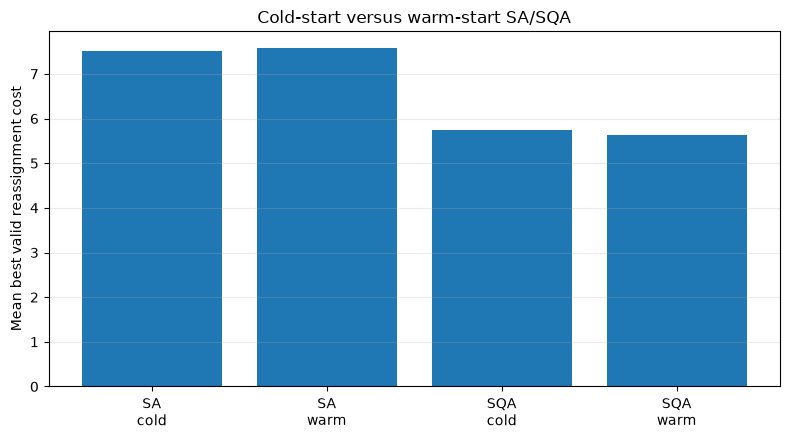

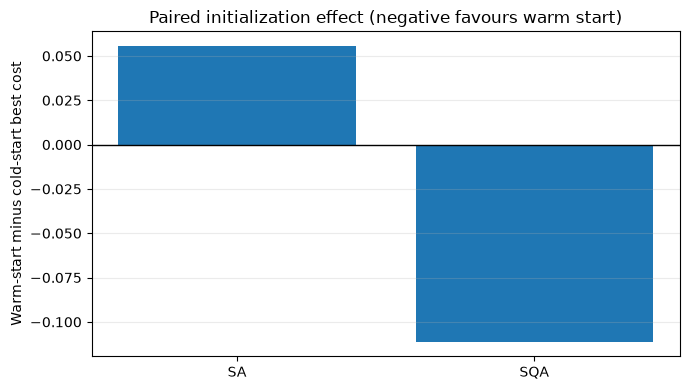

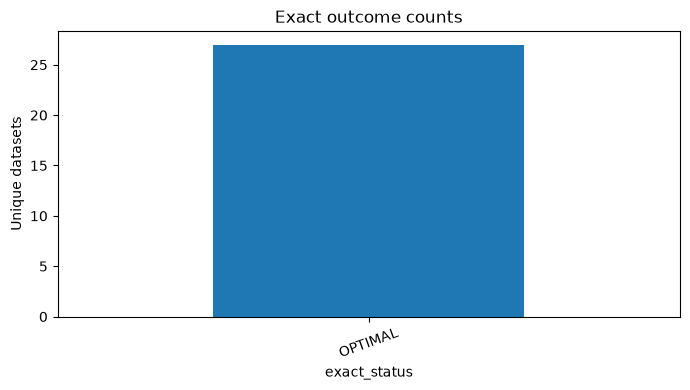

In [12]:
# Mean best valid sample cost by algorithm and start mode
plot_df = summary_by_mode.dropna(subset=["mean_best_sampler_cost"])
if not plot_df.empty:
    labels = [f"{r.algorithm}\n{r.start_mode}" for r in plot_df.itertuples()]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.bar(labels, plot_df.mean_best_sampler_cost)
    ax.set_ylabel("Mean best valid reassignment cost")
    ax.set_title("Cold-start versus warm-start SA/SQA")
    ax.grid(axis="y", alpha=.25)
    plt.tight_layout()
    plt.show()

if "warm_minus_cold_cost" in paired_comparison:
    delta = paired_comparison.groupby("algorithm").warm_minus_cold_cost.mean()
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(delta.index, delta.values)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_ylabel("Warm-start minus cold-start best cost")
    ax.set_title("Paired initialization effect (negative favours warm start)")
    ax.grid(axis="y", alpha=.25)
    plt.tight_layout()
    plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
status_counts = dataset_diagnostics.exact_status.value_counts()
status_counts.plot(kind="bar", ax=ax)
ax.set_ylabel("Unique datasets")
ax.set_title("Exact outcome counts")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 12. Export all v4 artefacts

Keep these files together with the executed notebook. They allow us to audit the exact same schedules and compare v4 against v3.

In [13]:
def export_frame(frame, filename):
    if frame is None or frame.empty:
        print(f"Skipped empty frame: {filename}")
        return
    frame.to_csv(filename, index=False)
    print(f"Saved {filename} ({len(frame)} rows)")

export_frame(dataset_diagnostics, "jaipur_v4_dataset_diagnostics.csv")
export_frame(generated_train_tables, "jaipur_v4_generated_train_tables.csv")
export_frame(conflict_edge_tables, "jaipur_v4_conflict_edges.csv")
export_frame(sampler_runs, "jaipur_v4_sampler_runs.csv")
export_frame(summary_by_mode, "jaipur_v4_summary_by_mode.csv")
export_frame(paired_comparison, "jaipur_v4_paired_comparison.csv")
export_frame(greedy_summary, "jaipur_v4_greedy_summary.csv")
export_frame(effort_sensitivity_results, "jaipur_v4_effort_sensitivity.csv")

metadata = {
    "notebook_version": "v4",
    "python_version": sys.version.split()[0],
    "platform": platform.platform(),
    "cpu": platform.processor(),
    "ram_gb": RAM_GB,
    "openjij_version": OPENJIJ_VERSION,
    "n_platforms": N_PLATFORMS,
    "clearance_min_assumption": BASE_CLEARANCE_MIN,
    "train_counts": TRAIN_COUNTS,
    "delay_levels_min": DELAY_LEVELS_MIN,
    "dataset_seeds": DATASET_SEEDS,
    "solver_repeats": SOLVER_REPEATS,
    "num_reads": NUM_READS,
    "num_sweeps": NUM_SWEEPS,
    "exact_time_limit_s": EXACT_TIME_LIMIT_S,
    "greedy_restarts": GREEDY_RESTARTS,
    "warm_start_perturbations_target": WARM_START_PERTURBATIONS,
    "run_28_train_benchmark": RUN_28_TRAIN_BENCHMARK,
    "qubo_identity_check": qubo_check,
    "warm_start_api_probe": warm_api_probe,
}
with open("jaipur_v4_experiment_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)
print("Saved jaipur_v4_experiment_metadata.json")

Saved jaipur_v4_dataset_diagnostics.csv (27 rows)
Saved jaipur_v4_generated_train_tables.csv (270 rows)
Saved jaipur_v4_conflict_edges.csv (183 rows)
Saved jaipur_v4_sampler_runs.csv (216 rows)
Saved jaipur_v4_summary_by_mode.csv (4 rows)
Saved jaipur_v4_paired_comparison.csv (108 rows)
Saved jaipur_v4_greedy_summary.csv (1 rows)
Saved jaipur_v4_effort_sensitivity.csv (24 rows)
Saved jaipur_v4_experiment_metadata.json


## 13. Interpretation checklist and decision gate

Before using v4 in the paper, check all of the following:

- The 27 dataset IDs match v3 exactly.
- QUBO identity verification passes.
- Every greedy and perturbed warm-start assignment is independently validated as feasible.
- Warm-start API support is reported separately for SA and SQA. Do not label a run warm-started if `initial_state` was rejected.
- Report Exact Search outcomes (`OPTIMAL`, `INFEASIBLE`, `TIMEOUT`) separately.
- Report greedy initializer performance as a separate classical heuristic baseline. If it matches Exact on every small instance, state that transparently; it suggests the current small test set is easy for a conflict-aware heuristic.
- Compare cold and warm runs on identical data, penalties, reads, sweeps and paired random seeds.
- `best_valid_cost` is the sampler's best output. `best_seen_including_start` includes the supplied start and must not be attributed to the annealer alone.
- Compare exact optimality gaps only on instances where Exact proved `OPTIMAL`.
- Keep the 28-train benchmark disabled until the small-instance results are understood.

### Decision gate

**Proceed to the 28-train stage only after we know:**
1. whether the greedy initializer already solves every small instance;
2. whether OpenJij accepts warm starts for both samplers;
3. whether warm-started SA/SQA improve on the deliberately perturbed feasible starting state;
4. whether any annealer hits the proven exact optimum on repeated runs.

If greedy repeatedly matches Exact and annealers do not improve the perturbed warm starts, the honest conclusion is that the current formulation/instances do not yet provide a strong basis for claiming an SQA advantage. The next research step would be to design a more structurally challenging but still defensible synthetic benchmark—not to manipulate results.